# Sales Prediction Using Regression

This notebook uses a small, assignment-based retail dataset to explore regression models for estimating store sales. It includes preprocessing, five model types, a sample new-store prediction, and evaluation on a held-out test split.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

### Define and inspect the assignment dataset

## Question 1: Regression Suitability

Regression is suitable because `Sales` is a numeric outcome and the task is to estimate it from advertising, store size, customer count, and promotion status. This notebook is a learning exercise: its ten observations are too few to support strong conclusions about performance on future stores.

## Question 2: Data Preprocessing

The ten-row assignment dataset is defined directly in this notebook, so no external data file is needed. The workflow checks the data, fills missing numerical predictor values with medians, encodes promotion status, and standardizes the three numerical predictors.


In [2]:
data = {
    "Advertising_Spend": [2000, 3000, 2500, 4000, 3500, None, 5000, 4500, 3000, 3800],
    "Store_Size": [1500, 2000, 1800, 2200, None, 2100, 2500, 2400, 2000, 2300],
    "Customers": [200, 250, 230, 300, 280, 260, 320, 310, 270, None],
    "Promotion": ["Yes", "No", "Yes", "Yes", "No", "No", "Yes", "Yes", "No", "Yes"],
    "Sales": [40000, 50000, 45000, 60000, 52000, 48000, 65000, 63000, 51000, 59000]
}


In [3]:
df = pd.DataFrame(data)

In [4]:
# Display the dataframe
print(df)

   Advertising_Spend  Store_Size  Customers Promotion  Sales
0             2000.0      1500.0      200.0       Yes  40000
1             3000.0      2000.0      250.0        No  50000
2             2500.0      1800.0      230.0       Yes  45000
3             4000.0      2200.0      300.0       Yes  60000
4             3500.0         NaN      280.0        No  52000
5                NaN      2100.0      260.0        No  48000
6             5000.0      2500.0      320.0       Yes  65000
7             4500.0      2400.0      310.0       Yes  63000
8             3000.0      2000.0      270.0        No  51000
9             3800.0      2300.0        NaN       Yes  59000


In [5]:
# Inspect the dataframe's structure and summary statistics
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Advertising_Spend  9 non-null      float64
 1   Store_Size         9 non-null      float64
 2   Customers          9 non-null      float64
 3   Promotion          10 non-null     object 
 4   Sales              10 non-null     int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 532.0+ bytes


,Advertising_Spend,Store_Size,Customers,Sales
count,9.000000,9.000000,9.000000,10.000000
mean,3477.777778,2088.888889,268.888889,53300.000000
std,957.572161,310.017921,38.873013,8165.646195
min,2000.000000,1500.000000,200.000000,40000.000000
25%,3000.000000,2000.000000,250.000000,48500.000000
50%,3500.000000,2100.000000,270.000000,51500.000000
75%,4000.000000,2300.000000,300.000000,59750.000000
max,5000.000000,2500.000000,320.000000,65000.000000


In [6]:
# check for missing values
print("\nMISSING VALUES BEFORE PREPROCESSING")
print(df.isnull().sum())



MISSING VALUES BEFORE PREPROCESSING
Advertising_Spend    1
Store_Size           1
Customers            1
Promotion            0
Sales                0
dtype: int64


### Check missing values and prepare the data

In [7]:
#Checking for missing values in the dataset before preprocessing, we can see that there are missing values in the 'Advertising_Spend', 'Store_Size', and 'Customers' columns.
print("\nMISSING VALUES BEFORE PREPROCESSING")
print(df.isnull().sum())


MISSING VALUES BEFORE PREPROCESSING
Advertising_Spend    1
Store_Size           1
Customers            1
Promotion            0
Sales                0
dtype: int64


In [8]:
#Handling missing values
#Creating a copy of the original dataframe to handle missing values
df_clean = df.copy()

In [9]:
# identifying the columns with missing values
missing_columns = df_clean.columns[df_clean.isnull().any()]
print("\nColumns with missing values:")
print(missing_columns)


Columns with missing values:
Index(['Advertising_Spend', 'Store_Size', 'Customers'], dtype='object')


In [10]:
#Identify numerical predictor columns
numerical_features = ["Advertising_Spend", "Store_Size", "Customers"]

In [11]:
# Replacing missing values in numerical columns with the median of the respective columns
for column in numerical_features:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)

print("\nMISSING VALUES AFTER PREPROCESSING")
print(df_clean.isnull().sum())


MISSING VALUES AFTER PREPROCESSING
Advertising_Spend    0
Store_Size           0
Customers            0
Promotion            0
Sales                0
dtype: int64


The **median** is used to fill missing values because it is less sensitive to extreme values than the mean. With only ten observations, this is a simple assignment choice; the small sample provides limited information about each feature's distribution.


In [12]:
# Step 3: Convert categorical variables(Promotion) to numerical format
# Yes = 1, No = 0
df_clean['Promotion'] = df_clean['Promotion'].map({'Yes': 1, 'No': 0})
print(df_clean[['Promotion']].head())

   Promotion
0          1
1          0
2          1
3          1
4          0


`Promotion` records whether an offer was active. It is encoded as **Yes = 1** and **No = 0**, allowing the regression models to use this binary predictor.


In [13]:
# Standardize the numerical predictor features

#Importing the StandardScaler from sklearn
from sklearn.preprocessing import StandardScaler    

#Initializing the StandardScaler
scaler = StandardScaler()

#Standardizing the numerical predictor columns
df_clean[numerical_features] = scaler.fit_transform(df_clean[numerical_features])

print("\nStandardized numerical features:")
print(df_clean[numerical_features].head())


Standardized numerical features:
   Advertising_Spend  Store_Size  Customers
0          -1.727954   -2.127594  -1.984431
1          -0.560417   -0.324548  -0.546437
2          -1.144185   -1.045767  -1.121635
3           0.607119    0.396670   0.891556
4           0.023351    0.036061   0.316359


### Why standardize the numerical features?

Standardization subtracts each numerical feature's mean and divides by its standard deviation. This gives `Advertising_Spend`, `Store_Size`, and `Customers` comparable scales, which is useful for Ridge and Lasso because their penalties depend on coefficient size. `Promotion` remains encoded as 0/1 and is not standardized, so the scaling is not identical across every predictor.


In [14]:
### Verifying the cleaned and preprocessed dataset
print('Missing values after preprocessing:')
print(df_clean.isnull().sum())

#Display the final cleaned and preprocessed dataset
print("\nCleaned and Preprocessed Dataset:")
print(df_clean)

#Check the dimensions of the cleaned and preprocessed dataset
print("\nDimensions of the cleaned and preprocessed dataset:", df_clean.shape)

Missing values after preprocessing:
Advertising_Spend    0
Store_Size           0
Customers            0
Promotion            0
Sales                0
dtype: int64

Cleaned and Preprocessed Dataset:
   Advertising_Spend  Store_Size  Customers  Promotion  Sales
0          -1.727954   -2.127594  -1.984431          1  40000
1          -0.560417   -0.324548  -0.546437          0  50000
2          -1.144185   -1.045767  -1.121635          1  45000
3           0.607119    0.396670   0.891556          1  60000
4           0.023351    0.036061   0.316359          0  52000
5           0.023351    0.036061  -0.258839          0  48000
6           1.774655    1.478498   1.466753          1  65000
7           1.190887    1.117889   1.179154          1  63000
8          -0.560417   -0.324548   0.028760          0  51000
9           0.373612    0.757279   0.028760          1  59000

Dimensions of the cleaned and preprocessed dataset: (10, 5)


### Methodology limitation: preprocessing before the split

For consistency with the submitted assignment, missing-value imputation and standardization are fitted on all ten rows before the train-test split. That allows information about the held-out predictors to influence the imputation medians and scaling parameters, so this evaluation is not fully leakage-free. A stronger workflow would split first and fit preprocessing steps on the training data only (for example, with a scikit-learn `Pipeline`), then apply those fitted steps to the test data. The metrics below should therefore be treated as a classroom demonstration, not a production estimate.


## Question 3: Regression Model Implementation and Predictions

The data is split into training and test sets with a 70/30 split and `random_state=42`. The notebook fits simple, multiple, and polynomial linear regression models, then uses the same training split for Ridge and Lasso regression.


In [15]:
# Define independent and dependent variables
X = df_clean.drop(columns=["Sales"])
y = df_clean["Sales"]

# Display the independent and dependent variables
print('Independent variables (X):')
display(X)
print('Dependent variable (y):')
display(y)

# Split the preprocessed dataset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

Independent variables (X):


,Advertising_Spend,Store_Size,Customers,Promotion
0,-1.727954,-2.127594,-1.984431,1
1,-0.560417,-0.324548,-0.546437,0
2,-1.144185,-1.045767,-1.121635,1
3,0.607119,0.396670,0.891556,1
4,0.023351,0.036061,0.316359,0
5,0.023351,0.036061,-0.258839,0
6,1.774655,1.478498,1.466753,1
7,1.190887,1.117889,1.179154,1
8,-0.560417,-0.324548,0.028760,0
9,0.373612,0.757279,0.028760,1


Dependent variable (y):


0    40000
1    50000
2    45000
3    60000
4    52000
5    48000
6    65000
7    63000
8    51000
9    59000
Name: Sales, dtype: int64

In [16]:
## Step 1: Simple Linear Regression Model
from sklearn.linear_model import LinearRegression

# Selecting single predictor (Advertising_Spend) variable for simple linear regression as the only predictor variable
X_train_simple = X_train[["Advertising_Spend"]]
X_test_simple = X_test[["Advertising_Spend"]]

# Create and train the simple linear regression model
Simple_LR_model = LinearRegression()
Simple_LR_model.fit(X_train_simple, y_train)

#predicting the sales using the simple linear regression model
simple_predictions = Simple_LR_model.predict(X_test_simple)

# Displaying the model coefficients
print("intercept:", Simple_LR_model.intercept_)
print("Advertising Spend coefficient:", Simple_LR_model.coef_[0])

#Displaying the actual vs predicted sales for the test set
results_simple = pd.DataFrame({"Actual Sales": y_test, "Predicted Sales": simple_predictions})
print("\nActual vs Predicted Sales (Simple Linear Regression):")
print(results_simple)

intercept:

 53676.88399661304
Advertising Spend coefficient: 7527.956783528427

Actual vs Predicted Sales (Simple Linear Regression):
   Actual Sales  Predicted Sales
8         51000     49458.086367
1         50000     49458.086367
5         48000     53852.667231


In [17]:
# Step 2: Multiple Linear Regression Model
# Create and train the multiple linear regression model
Multiple_LR_model = LinearRegression()
Multiple_LR_model.fit(X_train, y_train)

# Predict sales using the test dataset
multiple_predictions = Multiple_LR_model.predict(X_test)

# Displaying the model coefficients
print("intercept:", Multiple_LR_model.intercept_)

coefficients = pd.DataFrame({"Feature": X_train.columns, 
                             "Coefficient": Multiple_LR_model.coef_})
display(coefficients)

#Displaying the actual vs predicted sales for the test set
results_multiple = pd.DataFrame({"Actual Sales": y_test, "Predicted Sales": multiple_predictions})
print("\nActual vs Predicted Sales (Multiple Linear Regression):")
print(results_multiple)

intercept: 50978.65267613085


,Feature,Coefficient
0,Advertising_Spend,593.231905
1,Store_Size,4157.671239
2,Customers,2710.739294
3,Promotion,3640.772419



Actual vs Predicted Sales (Multiple Linear Regression):
   Actual Sales  Predicted Sales
8         51000     49374.790583
1         50000     47815.580637
5         48000     50440.790054


In [18]:
# Step 3: Polynomial regression with the numerical features and Promotion
from sklearn.preprocessing import PolynomialFeatures

numerical_features = [c for c in X_train.columns if c != 'Promotion']

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train[numerical_features])
X_test_poly = poly.transform(X_test[numerical_features])

feature_names = poly.get_feature_names_out(numerical_features)

X_train_poly_df = pd.DataFrame(
    X_train_poly,
    columns=feature_names,
    index=X_train.index
)
X_test_poly_df = pd.DataFrame(
    X_test_poly,
    columns=feature_names,
    index=X_test.index
)

X_train_poly_df['Promotion'] = X_train['Promotion']
X_test_poly_df['Promotion'] = X_test['Promotion']

polynomial_model = LinearRegression()
polynomial_model.fit(X_train_poly_df, y_train)

polynomial_predictions = polynomial_model.predict(X_test_poly_df)
display(pd.DataFrame({"Actual Sales": y_test, "Predicted Sales": polynomial_predictions}))  

,Actual Sales,Predicted Sales
8,51000,48197.431545
1,50000,46326.221656
5,48000,50768.552841


### Predict sales for a sample new store

The following example uses Advertising Spend = 4,200, Store Size = 2,100, Customers = 290, and Promotion = Yes. The three original prediction models are used for this example.


In [19]:
# Predict sales for a new store using all three models
new_store = pd.DataFrame({
    "Advertising_Spend": [4200],
    "Store_Size": [2100],
    "Customers": [290],
    "Promotion": [1]})

#Applying the same preprocessing steps to the new store data
#Standardizing the numerical features of the new store data
new_store[numerical_features] = scaler.transform(new_store[numerical_features])

# Predicting sales using the simple linear regression model
simple_sales_prediction = Simple_LR_model.predict(new_store[["Advertising_Spend"]])

# Predicting sales using the multiple linear regression model
multiple_sales_prediction = Multiple_LR_model.predict(new_store)

# Predicting sales using the polynomial regression model
new_store_poly_num = poly.transform(
    new_store[numerical_features]
)

# Convert polynomial features into a DataFrame
new_store_poly = pd.DataFrame(
    new_store_poly_num,
    columns=feature_names
)

# Add Promotion
new_store_poly["Promotion"] = new_store["Promotion"].to_numpy()

# Polynomial Regression prediction
polynomial_sales_prediction = polynomial_model.predict(
    new_store_poly
)

# Display the new-store predictions from all three models
print("\nPredicted Sales for the new store:")
print("Simple Linear Regression Prediction:", simple_sales_prediction[0])
print("Multiple Linear Regression Prediction:", multiple_sales_prediction[0])
print("Polynomial Regression Prediction:", polynomial_sales_prediction[0])


Predicted Sales for the new store:
Simple Linear Regression Prediction: 60005.080440304824
Multiple Linear Regression Prediction: 56905.2111806719
Polynomial Regression Prediction: 60378.52513226544


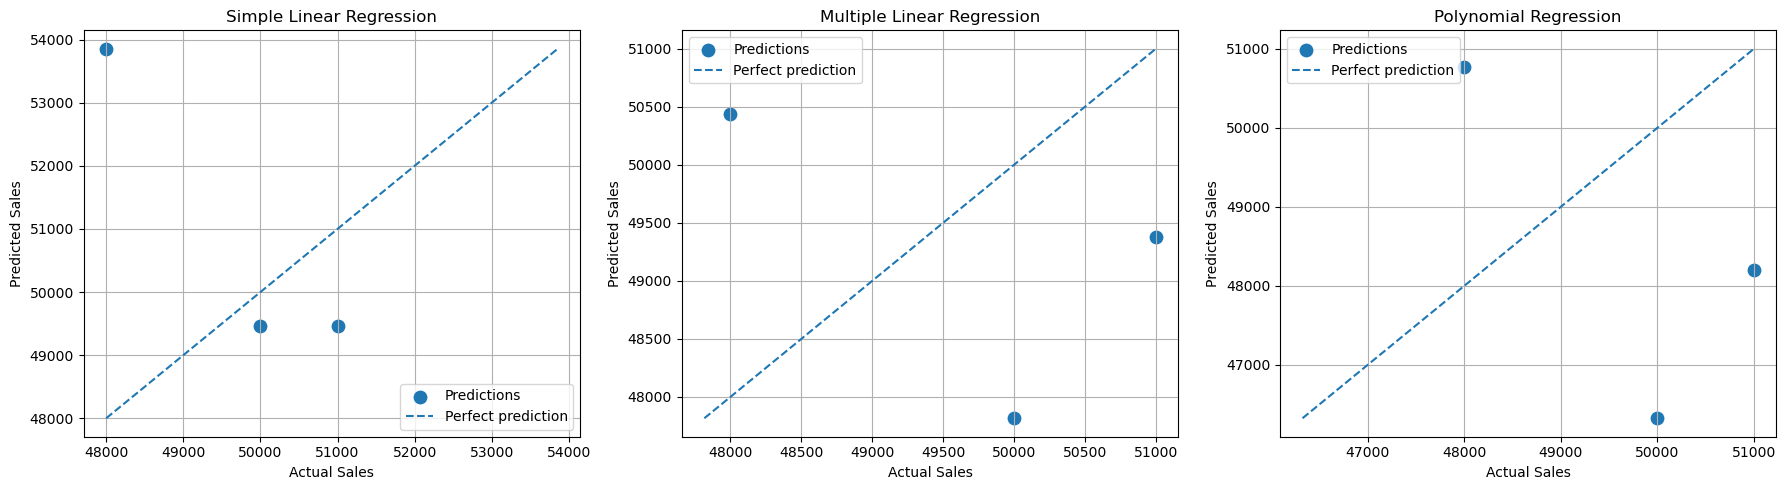

In [20]:
# Actual vs Predicted Sales for the test set using all three models
import matplotlib.pyplot as plt


# Save figures whether Jupyter is started from the project root or notebooks/.
from pathlib import Path

results_candidates = [Path.cwd() / "results", Path.cwd().parent / "results"]
results_dir = next((path for path in results_candidates if path.is_dir()), results_candidates[0])
results_dir.mkdir(parents=True, exist_ok=True)

# Create a figure with three subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ("Simple Linear Regression", Simple_LR_model.predict(X_test_simple)),
    ("Multiple Linear Regression", Multiple_LR_model.predict(X_test)),
    ("Polynomial Regression", polynomial_model.predict(X_test_poly_df))
]

for ax, (model_name, predictions) in zip(axes, models):

    # Plot actual vs predicted values
    ax.scatter(y_test, predictions, s=80, label="Predictions")

    # Add reference line for perfect predictions
    min_value = min(y_test.min(), predictions.min())
    max_value = max(y_test.max(), predictions.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        label="Perfect prediction"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual Sales")
    ax.set_ylabel("Predicted Sales")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
fig.savefig(results_dir / "actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

### Compare the first three models visually

These plots compare test-set actual sales with predictions from simple, multiple, and polynomial regression. Points closer to the dashed line have predictions closer to the observed sales. The test set contains only three rows, so the plots are descriptive rather than conclusive.


## Question 4: Model Evaluation, Regularisation, and Overfitting

In [21]:
# importing metrics for model evaluation
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import pandas as pd

In [22]:
# Generate predictions using the test data
simple_predictions = Simple_LR_model.predict(X_test_simple)

multiple_predictions = Multiple_LR_model.predict(X_test)

polynomial_predictions = polynomial_model.predict(X_test_poly_df)


# Store the models and their predictions
models = {
    "Simple Linear Regression": simple_predictions,
    "Multiple Linear Regression": multiple_predictions,
    "Polynomial Regression": polynomial_predictions
}


# Calculate evaluation metrics
evaluation_results = []

for model_name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })


# Display the evaluation results
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(2))

,Model,MAE,RMSE,R²
0,Simple Linear Regression,2645.50,3508.32,-6.91
1,Multiple Linear Regression,2083.47,2111.12,-1.87
2,Polynomial Regression,3081.63,3109.98,-5.22


Among the first three models, multiple linear regression has the lowest test-set MAE and RMSE on this split. The R² values are negative, meaning each model performs worse on these three test rows than predicting their mean sales. With only three test observations, these comparisons are highly unstable.


In [23]:
## Applying Ridge Regression and Lasso Regression for regularization
from sklearn.linear_model import Ridge, Lasso

#Create the Ridge and lasso regression models
ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=1.0, max_iter=100000)

#Train the models
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

#Generate predictions using the test data
ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

#Evaluate both models
regularized_models = []
for model_name, predictions in [("Ridge Regression", ridge_predictions), ("Lasso Regression", lasso_predictions)]:
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    regularized_models.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Display the evaluation results for regularized models
regularized_evaluation_df = pd.DataFrame(regularized_models)
display(regularized_evaluation_df.round(2))

,Model,MAE,RMSE,R²
0,Ridge Regression,1834.80,2562.04,-3.22
1,Lasso Regression,2086.41,2114.93,-1.88


In [24]:
# Combine predictions from all five models
all_models = {
    "Simple Linear Regression": simple_predictions,
    "Multiple Linear Regression": multiple_predictions,
    "Polynomial Regression": polynomial_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions
}

# Compare model performance
comparison = []

for name, predictions in all_models.items():
    comparison.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R²": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(2))

,Model,RMSE,MAE,R²
0,Simple Linear Regression,3508.32,2645.50,-6.91
1,Multiple Linear Regression,2111.12,2083.47,-1.87
2,Polynomial Regression,3109.98,3081.63,-5.22
3,Ridge Regression,2562.04,1834.80,-3.22
4,Lasso Regression,2114.93,2086.41,-1.88


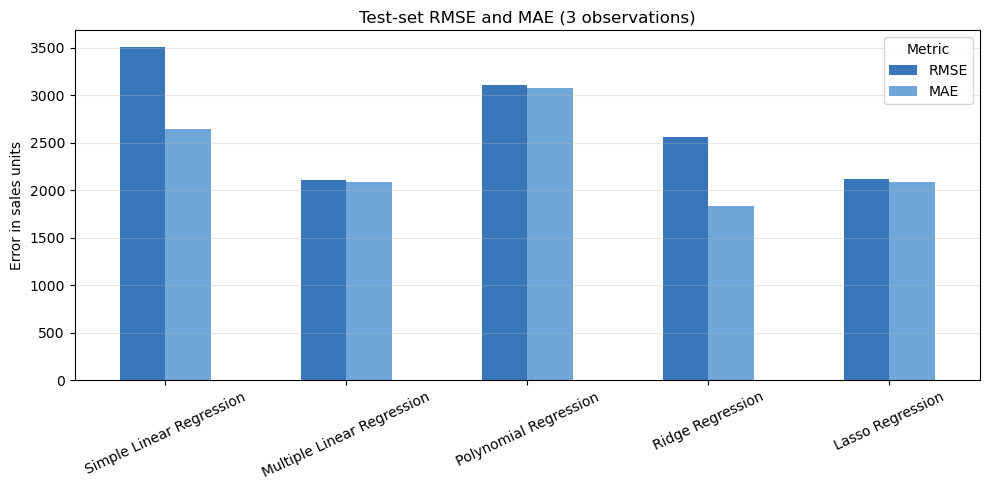

In [25]:
# Compare test-set error metrics for all five models.
ax = comparison_df.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar", figsize=(10, 5), color=["#3976B9", "#70A6D8"]
)
ax.set_title("Test-set RMSE and MAE (3 observations)")
ax.set_xlabel("")
ax.set_ylabel("Error in sales units")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Metric")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(results_dir / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


On this split, multiple linear regression has the lowest RMSE (2,111.12) and the least-negative R² (-1.87). Ridge has the lowest MAE (1,834.80). All five R² values are negative, so every model performs worse on these three test observations than the test-set mean baseline. The ranking is highly sensitive to such a small test set.


In [26]:
## Examine Overfitting and Underfitting
from sklearn.metrics import mean_squared_error
import numpy as np

model_comparison = {
    "Simple Linear Regression": (
        Simple_LR_model,
        X_train_simple,
        X_test_simple
    ),
    "Multiple Linear Regression": (
        Multiple_LR_model,
        X_train,
        X_test
    ),
    "Polynomial Regression": (
        polynomial_model,
        X_train_poly_df,
        X_test_poly_df
    ),
    "Ridge Regression": (
        ridge_model,
        X_train,
        X_test
    ),
    "Lasso Regression": (
        lasso_model,
        X_train,
        X_test
    )
}

overfitting_results = []

for name, (model, X_tr, X_te) in model_comparison.items():

    train_predictions = model.predict(X_tr)
    test_predictions = model.predict(X_te)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

    overfitting_results.append({
        "Model": name,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(2))

,Model,Training RMSE,Testing RMSE
0,Simple Linear Regression,1582.69,3508.32
1,Multiple Linear Regression,865.95,2111.12
2,Polynomial Regression,0.00,3109.98
3,Ridge Regression,1147.89,2562.04
4,Lasso Regression,865.97,2114.93


Training and test RMSE provide a simple check for differences in fit. Polynomial regression has a training RMSE of 0.00 and a test RMSE of 3,109.98, consistent with overfitting on this tiny training sample. Multiple linear regression has training RMSE of 865.95 and test RMSE of 2,111.12. These values do not establish how any model will perform on new data: the dataset has ten observations and only three test observations, and preprocessing was performed before the split as described above.
